# 6.0 · Modelado y Evaluación sin Fuga (Fase 4 CRISP-DM)

**CRISP-DM fase 4 y 5 · Modeling & Evaluation**  
**Proyecto:** JobPath · patrones de transición y reincidencia ocupacional  
**Cuaderno de cierre de recomendaciones del EDA**

---

## Ficha de la sesión

| Elemento | Detalle |
|---|---|
| Cuaderno | `notebooks/refactor/6.0_modelado_fase4_jobpath.ipynb` |
| Lógica pesada | `scripts/ScriptsCsv/Modelado/` (paquete modular SOLID importado) |
| Insumos (solo lectura) | `data/03_processed/` (versiones A y B), `data/04_transformed/` y `reports/eda_jobpath/tables/split_map_resume_id.csv` |
| Salidas | `reports/modelado_jobpath/figures/` (4 figuras M01–M04) y `reports/modelado_jobpath/tables/` (5 tablas CSV) |
| Semilla | `42` |
| Validación cruzada | `StratifiedGroupKFold(n_splits=5, group=resume_id)` exclusivamente sobre `train` (`1,391,018` filas · `281,674` personas) |
| Evaluación final | Partición `test` por persona (`347,720` filas · `70,419` personas · `0` personas solapadas) |

Este cuaderno ejecuta las cinco recomendaciones obligatorias que dejó `5.0_EDA_jobpath.ipynb` (§15.4):

1. **Excluir de `X` las variables con fuga directa del target:** `veces_ese_oficio`, `veces_ese_oficio_rob` y `veces_ese_oficio_bin` (que reproducen el `100.00 %` de `reincide`), así como prohibir `n_returns` y `n_nonadjacent_returns`.
2. **Controlar la colinealidad:** retirar las variables redundantes por construcción (`start_year_rob` por $r = 1.000$ con `start_ord_rob`, y `n_skills_competence_rob` por $r = 0.952$ con `n_skills_essential_rob`).
3. **Respetar la agrupación por persona (`resume_id`):** evaluar modelos con `StratifiedGroupKFold` en `train` y medir generalización en personas nuevas en `test`.
4. **Usar métricas sensibles al desbalance moderado (`30.01 %` de positivos):** **PR-AUC (`average_precision_score`), F1 de la clase positiva, Recall, Precisión, Exactitud Balanceada y ROC-AUC**.
5. **Comparar formalmente la Versión A (`con_outliers`) frente a la Versión B (`sin_outliers`, IQR):** determinar con evidencia ejecutada si el recorte IQR altera la capacidad predictiva.

## 1. Preparación del entorno e importación de librerías

**¿Qué hace?** Importa todas las librerías y el paquete modular `scripts.ScriptsCsv.Modelado` en la primera celda de código, resuelve la raíz del proyecto de forma relativa y toma la huella SHA-256 inicial de todos los insumos.

**¿Por qué existe?** Garantiza la ejecución limpia de principio a fin (`Run All`) y permite demostrar al cierre del cuaderno que ningún archivo de `data/03_processed/` ni de `data/04_transformed/` fue modificado.

**¿Qué recibe y qué entrega?** Recibe la estructura del repositorio. Entrega `CONFIG`, `PIPELINE` y el diccionario `SNAPSHOT_BEFORE` con las huellas SHA-256 iniciales.

**Papel en el proyecto.** Abre la Fase 4 manteniendo intacta la reproducibilidad de las fases 2.0, 3.0, 4.0, 4.1 y 5.0.

In [1]:
from pathlib import Path
import sys
import warnings

from IPython.display import Image, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.4f}".format)

PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "data").is_dir() and (PROJECT_ROOT / "notebooks").is_dir()):
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

from scripts.ScriptsCsv.Modelado import (
    COLLINEAR_REDUNDANT_FEATURES,
    LEAKAGE_FEATURES_IN_X,
    ModelingConfig,
    ModelingPipeline,
    VERSION_CON,
    VERSION_SIN,
)

CONFIG = ModelingConfig(project_root=PROJECT_ROOT, random_state=42, cv_folds=5)
PIPELINE = ModelingPipeline(CONFIG)
SNAPSHOT_BEFORE = PIPELINE.snapshot_inputs()

print(f"Raíz del proyecto: {CONFIG.project_root}")
print(f"Semilla aleatoria fija: {CONFIG.random_state} | Pliegues CV por persona: {CONFIG.cv_folds}")
print(f"Columnas de fuga bloqueadas: {list(CONFIG.leakage_features)}")
print(f"Columnas colineales retiradas: {list(CONFIG.collinear_drop_features)}")
print(f"Insumos registrados en huella SHA-256 inicial: {len(SNAPSHOT_BEFORE)}")

Raíz del proyecto: C:\Users\User\Documents\JobPath\MineriaProtect
Semilla aleatoria fija: 42 | Pliegues CV por persona: 5
Columnas de fuga bloqueadas: ['veces_ese_oficio_rob', 'veces_ese_oficio_bin']
Columnas colineales retiradas: ['start_year_rob', 'n_skills_competence_rob']
Insumos registrados en huella SHA-256 inicial: 13


**Lectura.** El entorno queda inicializado con semilla `42` y `13` archivos de entrada protegidos mediante huella SHA-256. La exclusión de las columnas de fuga (`veces_ese_oficio_rob`, `veces_ese_oficio_bin`) y de colinealidad extrema (`start_year_rob`, `n_skills_competence_rob`) se realiza exclusivamente en memoria RAM, sin alterar los CSV exportados por el cuaderno `3.0`.

## 2. Construcción de matrices sin fuga y verificación contra `04_transformed`

**¿Qué hace?** Reconstruye las particiones `train` (`1,391,018` filas · `281,674` personas) y `test` (`347,720` filas · `70,419` personas) para las versiones **A (`con_outliers`)** y **B (`sin_outliers`)**, verifica su igualdad numérica contra `X_train.csv` (`max_diff = 0.0`) y audita el estado de las 18 variables densas antes de ensamblar la matriz dispersa `CSR` con las `2,967` dummies `occupation_code_*`.

**¿Por qué existe?** Permite trabajar en memoria con la matriz completa de `1.39M × 2,981` en formato disperso (`scipy.sparse.csr_matrix`) en pocos segundos, garantizando al mismo tiempo que el conjunto de datos coincide fila a fila con los archivos exportados en `data/04_transformed/`.

**¿Qué recibe y qué entrega?** Recibe los CSV limpios de `03_processed/`, los `y_*.csv` y los `transformers.joblib`. Entrega los objetos `DATA_A` y `DATA_B`, la tabla de verificación de dimensiones y la tabla de auditoría de las 18 columnas densas.

**Papel en el proyecto.** Cierra el puente técnico entre la Fase 3 (Transformación) y la Fase 4 (Modelado), certificando `fuga_eliminada = True` y `personas_solapadas = 0`.

In [2]:
DATA_A = PIPELINE.builder.build_version(VERSION_CON)
DATA_B = PIPELINE.builder.build_version(VERSION_SIN)

verif_df = pd.DataFrame([DATA_A.verification, DATA_B.verification])
display(verif_df)
display(DATA_A.feature_audit_table)

,version,filas_train,filas_test,personas_train,personas_test,personas_solapadas,cols_originales_x,cols_sin_fuga_x,cols_limpias_sin_colinealidad_x,cols_densas_limpias,cols_dummies_ocupacion,max_diff_vs_x_train_csv,fuga_eliminada
0,con_outliers,1391018,347720,281674,70419,0,2985,2983,2981,14,2967,0.0000,True
1,sin_outliers,1391018,347720,281674,70419,0,2985,2983,2981,14,2967,0.0000,True


,variable,corr_train_con_target,estado_fase4,justificacion
0,start_ord_rob,0.0418,CONSERVADA (Feature legítima),Variable predictora válida sin circularidad co...
1,end_ord_rob,-0.0001,CONSERVADA (Feature legítima),Variable predictora válida sin circularidad co...
2,dur_q_rob,-0.0717,CONSERVADA (Feature legítima),Variable predictora válida sin circularidad co...
3,n_skills_essential_rob,0.0715,CONSERVADA (Feature legítima),Variable predictora válida sin circularidad co...
4,n_skills_competence_rob,0.0815,EXCLUIDA (Colinealidad alta),Redundante con n_skills_essential_rob (r = 0.9...
5,n_skills_knowledge_rob,0.0090,CONSERVADA (Feature legítima),Variable predictora válida sin circularidad co...
6,n_skills_sin_tipo_rob,-0.0249,CONSERVADA (Feature legítima),Variable predictora válida sin circularidad co...
7,veces_ese_oficio_rob,0.7597,EXCLUIDA (Fuga directa 100 %),Reproduce exactamente la definición reincide =...
8,start_year_rob,0.0405,EXCLUIDA (Colinealidad alta),Redundante con start_ord_rob (r = 1.000).
9,job_order_rob,0.1237,CONSERVADA (Feature legítima),Variable predictora válida sin circularidad co...


**Lectura.** La verificación confirma tres hechos fundamentales:
1. **Alineación exacta (`max_diff_vs_x_train_csv = 0.0000`):** Las matrices reconstruidas coinciden exactamente con los archivos de `data/04_transformed/` en las `1,391,018` filas de `train` (`281,674` personas) y `347,720` filas de `test` (`70,419` personas), con `0` personas solapadas.
2. **Eliminación verificada de fuga (`fuga_eliminada = True`):** Al retirar `veces_ese_oficio_rob` ($r = 0.7604$ con `reincide`) y `veces_ese_oficio_bin` ($r = 0.9032$), la matriz pasa de `2,985` a `2,983` columnas.
3. **Control de colinealidad:** Al retirar además `start_year_rob` ($r = 1.000$ con `start_ord_rob`) y `n_skills_competence_rob` ($r = 0.952$ con `n_skills_essential_rob`), quedan **`2,981` features legítimas** (`14` variables densas de trayectoria, calendario, duración, educación y competencias + `2,967` dummies `occupation_code_*`).

## 3. Estudio de ablación (con fuga vs. sin fuga vs. sin colinealidad) y evaluación A/B

**¿Qué hace?** Ejecuta validación cruzada de 5 pliegues agrupada por persona (`StratifiedGroupKFold(n_splits=5, group=resume_id)`) sobre las `1,391,018` filas de `train` y evalúa los modelos finales sobre las `347,720` filas de `test` para tres familias de clasificadores:
1. **Baseline (`DummyClassifier`):** Predicción por prevalencia base (`30.01 %`).
2. **Regresión Logística Regularizada (`SGDClassifier(loss='log_loss', penalty='l2', class_weight='balanced')`):** Modelo lineal interpretable sobre las **`2,981` columnas** (`14` densas + `2,967` ocupaciones OHE).
3. **Boosting de Gradiente (`HistGradientBoostingClassifier(class_weight='balanced')`):** Modelo no lineal de árboles sobre las **`14` variables densas** sin fuga ni colinealidad.

**¿Por qué existe?** Responde con evidencia cuantitativa tres preguntas clave de la rúbrica: cuánto inflaba la fuga el resultado, si quitar las colineales degrada el modelo y si existe diferencia real entre modelar con la **Versión A (`con_outliers`)** o con la **Versión B (`sin_outliers`, IQR)**.

**¿Qué recibe y qué entrega?** Recibe `DATA_A` y `DATA_B`. Entrega `EVAL_BUNDLE` con la tabla de ablación, la tabla de validación cruzada 5-fold por persona y la tabla de desempeño fuera de muestra en `test`.

**Papel en el proyecto.** Sustenta la selección del modelo y de la versión de datos con métricas sensibles al desbalance (**PR-AUC, F1 positiva, Recall, Precisión, Exactitud Balanceada y ROC-AUC**).

In [3]:
EVAL_BUNDLE = PIPELINE.evaluator.evaluate_versions(DATA_A, DATA_B)

print("Control de agrupación en validación cruzada:", EVAL_BUNDLE.cv_leak_check)
print("\n=== 3.1 Estudio de ablación en Train (CV 5-fold por persona · Versión A) ===")
display(EVAL_BUNDLE.ablation_table)

print("\n=== 3.2 Resultados en Validación Cruzada 5-Fold por persona (Train · 1,391,018 filas) ===")
display(EVAL_BUNDLE.cv_summary_table)

print("\n=== 3.3 Resultados fuera de muestra en Test por persona (Test · 347,720 filas) ===")
display(EVAL_BUNDLE.test_summary_table)

Control de agrupación en validación cruzada: {'n_splits': 5, 'splitter': 'StratifiedGroupKFold(group=resume_id)', 'personas_solapadas_entre_folds': 0}

=== 3.1 Estudio de ablación en Train (CV 5-fold por persona · Versión A) ===


,esquema_features,n_columnas,pr_auc_cv_media,pr_auc_cv_std,roc_auc_cv_media,f1_pos_cv_media,recall_pos_cv_media,precision_pos_cv_media,balanced_acc_cv_media
0,1. Con fuga (prohibido),2985,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,"2. Sin fuga (2,983 cols)",2983,0.5111,0.0027,0.7131,0.5338,0.6304,0.4635,0.6584
2,"3. Sin fuga + sin colinealidad (2,981 cols)",2981,0.5113,0.0029,0.7132,0.5340,0.6313,0.4635,0.6586



=== 3.2 Resultados en Validación Cruzada 5-Fold por persona (Train · 1,391,018 filas) ===


,version,modelo,pr_auc_cv,pr_auc_std,roc_auc_cv,f1_pos_cv,recall_pos_cv,precision_pos_cv,balanced_acc_cv
0,A · con outliers,Baseline (Prior),0.3001,0.0000,0.5000,0.0000,0.0000,0.0000,0.5000
1,A · con outliers,"Logística Regularizada (OHE 2,981 cols)",0.5113,0.0029,0.7132,0.5340,0.6313,0.4635,0.6586
2,A · con outliers,HistGradientBoosting (14 cols densas),0.4963,0.0023,0.6935,0.5140,0.6082,0.4451,0.6415
3,B · sin outliers (IQR),Baseline (Prior),0.3001,0.0000,0.5000,0.0000,0.0000,0.0000,0.5000
4,B · sin outliers (IQR),"Logística Regularizada (OHE 2,981 cols)",0.5112,0.0029,0.7133,0.5341,0.6315,0.4634,0.6586
5,B · sin outliers (IQR),HistGradientBoosting (14 cols densas),0.4895,0.0022,0.6911,0.5127,0.6099,0.4422,0.6400



=== 3.3 Resultados fuera de muestra en Test por persona (Test · 347,720 filas) ===


,version,modelo,pr_auc_test,roc_auc_test,f1_pos_test,recall_pos_test,precision_pos_test,balanced_acc_test,brier_test
0,A · con outliers,Baseline (Prior),0.2997,0.5000,0.0000,0.0000,0.0000,0.5000,0.2099
1,A · con outliers,"Logística Regularizada (OHE 2,981 cols)",0.5109,0.7133,0.5321,0.6147,0.4691,0.6585,0.2108
2,A · con outliers,HistGradientBoosting (14 cols densas),0.4951,0.6936,0.5151,0.6109,0.4453,0.6426,0.2211
3,B · sin outliers (IQR),Baseline (Prior),0.2997,0.5000,0.0000,0.0000,0.0000,0.5000,0.2099
4,B · sin outliers (IQR),"Logística Regularizada (OHE 2,981 cols)",0.5109,0.7132,0.5325,0.6162,0.4688,0.6587,0.2111
5,B · sin outliers (IQR),HistGradientBoosting (14 cols densas),0.4888,0.6912,0.5134,0.6129,0.4417,0.6407,0.2219


**Lectura.** Los resultados numéricos demuestran cada una de las hipótesis planteadas en el EDA:

1. **Efecto de la fuga del target (Tabla 3.1):** Cuando se incluyen por error `veces_ese_oficio_rob` y `veces_ese_oficio_bin`, el modelo obtiene un **PR-AUC artificial de `1.0000` y F1 de `1.0000`** porque la etiqueta está contenida en las features. Al eliminar las dos columnas con fuga, el clasificador mide la señal predictiva legítima del historial laboral (**PR-AUC CV = `0.5111`**, **ROC-AUC CV = `0.7131`**, **F1 positiva = `0.5338`**, **Recall positiva = `0.6304`** frente al azar de `0.3001` en PR-AUC).
2. **Efecto del control de colinealidad (Tabla 3.1):** Al retirar `start_year_rob` y `n_skills_competence_rob` (`2,983 → 2,981` columnas), las métricas se mantienen e incluso mejoran levemente (**PR-AUC CV pasa de `0.5111` a `0.5113`**, **ROC-AUC CV de `0.7131` a `0.7132`** y **F1 positiva de `0.5338` a `0.5340`**), confirmando que eran redundantes y que retirarlas limpia la interpretación sin perder señal.
3. **Comparación de modelos (Tablas 3.2 y 3.3):**
   - `HistGradientBoosting` sobre las `14` variables densas captura relaciones no lineales de orden del empleo y duración (**PR-AUC en test = `0.4951`**, **ROC-AUC = `0.6936`**, **F1 positiva = `0.5151`**, **Recall = `0.6109`** en A).
   - La **Regresión Logística Regularizada con las `2,967` dummies de `occupation_code`** supera al modelo solo denso (**PR-AUC en test = `0.5109`**, **ROC-AUC = `0.7133`**, **F1 positiva = `0.5321`**, **Recall = `0.6147`**), demostrando que la identidad específica del oficio ESCO aporta información sustantiva sobre la propensión a reincidir.
4. **Comparación Versión A (`con_outliers`) vs. Versión B (`sin_outliers`, IQR):**
   - En `test` (`347,720` filas), la Regresión Logística OHE alcanza **PR-AUC = `0.5109`, ROC-AUC = `0.7133` y F1 = `0.5321`** en A frente a **PR-AUC = `0.5109`, ROC-AUC = `0.7132` y F1 = `0.5325`** en B; `HistGradientBoosting` obtiene **PR-AUC = `0.4951` y ROC-AUC = `0.6936`** en A frente a **`0.4888` y `0.6912`** en B.
   - ¿Por qué convergen A y B? Porque `RobustScaler` ya escala por mediana e IQR (que son idénticos entre A y B) y porque la variable donde el recorte IQR alteraba con mayor fuerza la cola era `veces_ese_oficio`, que fue excluida por fuga.

## 4. Importancia de variables legítimas e interpretación de negocio

**¿Qué hace?** Extrae los coeficientes estandarizados de la Regresión Logística Regularizada sobre las `14` variables densas legítimas (para A y B) y lista las `15` ocupaciones ESCO (`occupation_code_*`) con mayor peso absoluto en la predicción de `reincide`.

**¿Por qué existe?** Una vez eliminada la fuga, interesa responder en lenguaje de negocio **qué factores reales de la trayectoria se asocian con que una experiencia corresponda a un oficio repetido**.

**¿Qué recibe y qué entrega?** Recibe `EVAL_BUNDLE`. Entrega la tabla ordenada de coeficientes de las 14 variables densas y el top 15 de ocupaciones específicas.

**Papel en el proyecto.** Conecta el modelo supervisado de la Fase 4 con los hallazgos descriptivos del EDA (`5.0`).

In [4]:
print("=== 4.1 Peso y dirección de las 14 variables densas legítimas (Versión A vs. Versión B) ===")
display(EVAL_BUNDLE.feature_importance_table)

print("\n=== 4.2 Top 15 dummies de ocupación (occupation_code_*) con mayor magnitud de coeficiente ===")
display(EVAL_BUNDLE.top_occupations_table)

=== 4.1 Peso y dirección de las 14 variables densas legítimas (Versión A vs. Versión B) ===


,version,variable,coef_logistico,abs_coef,direccion
0,A · con outliers,tiene_skills,-0.4527,0.4527,Reduce prob. de reincidir (-)
1,A · con outliers,es_vigente,0.3816,0.3816,Aumenta prob. de reincidir (+)
2,A · con outliers,univ_ord_mm,-0.3138,0.3138,Reduce prob. de reincidir (-)
3,A · con outliers,job_order_rob,0.3128,0.3128,Aumenta prob. de reincidir (+)
4,A · con outliers,dur_q_bin,-0.1761,0.1761,Reduce prob. de reincidir (-)
5,A · con outliers,tiene_sin_tipo,-0.1222,0.1222,Reduce prob. de reincidir (-)
6,A · con outliers,tiene_knowledge,-0.1210,0.1210,Reduce prob. de reincidir (-)
7,A · con outliers,n_skills_essential_rob,0.0978,0.0978,Aumenta prob. de reincidir (+)
8,A · con outliers,start_ord_rob,-0.0842,0.0842,Reduce prob. de reincidir (-)
9,A · con outliers,dur_q_rob,-0.0793,0.0793,Reduce prob. de reincidir (-)



=== 4.2 Top 15 dummies de ocupación (occupation_code_*) con mayor magnitud de coeficiente ===


,feature_ocupacion,coef_logistico,abs_coef
0,occupation_code_3343.1,1.7416,1.7416
1,occupation_code_5312.1,1.7123,1.7123
2,occupation_code_2166.9,1.6732,1.6732
3,occupation_code_2330.1.12,1.6339,1.6339
4,occupation_code_2330.1,1.4799,1.4799
5,occupation_code_2264.2,1.4287,1.4287
6,occupation_code_2266.2,1.4115,1.4115
7,occupation_code_5321.1,1.3886,1.3886
8,occupation_code_5311.1,1.3689,1.3689
9,occupation_code_2330.1.15,1.3689,1.3689


**Lectura.** Sin columnas circulares, la estructura explicativa del modelo es totalmente coherente con los hallazgos del EDA:
- **Vigencia y orden del empleo en la trayectoria (`es_vigente` = `+0.3816`, `job_order_rob` = `+0.3128` en A / `+0.3137` en B):** A medida que una persona avanza hacia empleos posteriores dentro de su historial laboral, crece significativamente la probabilidad de que esté retornando a un oficio que ya había ejercido antes.
- **Nivel educativo (`univ_ord_mm`, coef = `-0.3138` en A / `-0.3045` en B):** Mayor nivel educativo declarado se asocia con menor repetición del mismo oficio (consistente con `G29`, donde máster y doctorado mostraron menor tasa de reincidencia que secundaria y grado).
- **Duración y calendario (`dur_q_bin` = `-0.1761`, `start_ord_rob` = `-0.0842`, `dur_q_rob` = `-0.0793`):** Las experiencias más cortas presentan mayor tasa de reincidencia/rotación que los empleos de larga permanencia (consistente con la figura `G28` del EDA).

## 5. Figuras de diagnóstico y evaluación (M01 a M04)

**¿Qué hace?** Genera y guarda en `reports/modelado_jobpath/figures/` las cuatro figuras del cierre de la Fase 4:
- **M01 (`m01_ablacion_fuga_y_colinealidad.png`):** Comparación en CV 5-fold por persona entre el esquema con fuga, sin fuga y sin colinealidad.
- **M02 (`m02_curvas_pr_y_roc_test.png`):** Curvas Precision-Recall y ROC en `test` (`347,720` filas · `70,419` personas).
- **M03 (`m03_comparacion_modelos_ab.png`):** Desempeño comparado entre la Versión A (`con_outliers`) y la Versión B (`sin_outliers`) en `test`.
- **M04 (`m04_importancia_variables_sin_fuga.png`):** Magnitud y signo de los coeficientes de las 14 variables densas legítimas.

**¿Por qué existe?** Documenta visualmente la ganancia sobre el azar, el efecto de eliminar la fuga y la equivalencia práctica entre A y B en una carpeta separada (`reports/modelado_jobpath/figures/`) para conservar intactas las 28 figuras del EDA en `reports/eda_jobpath/figures/`.

**¿Qué recibe y qué entrega?** Recibe `EVAL_BUNDLE`. Entrega los 4 archivos PNG y los visualiza en el cuaderno.

**Papel en el proyecto.** Evidencia gráfica lista para el informe de la Fase 4 y 5 de CRISP-DM.

M01: C:\Users\User\Documents\JobPath\MineriaProtect\reports\modelado_jobpath\figures\m01_ablacion_fuga_y_colinealidad.png


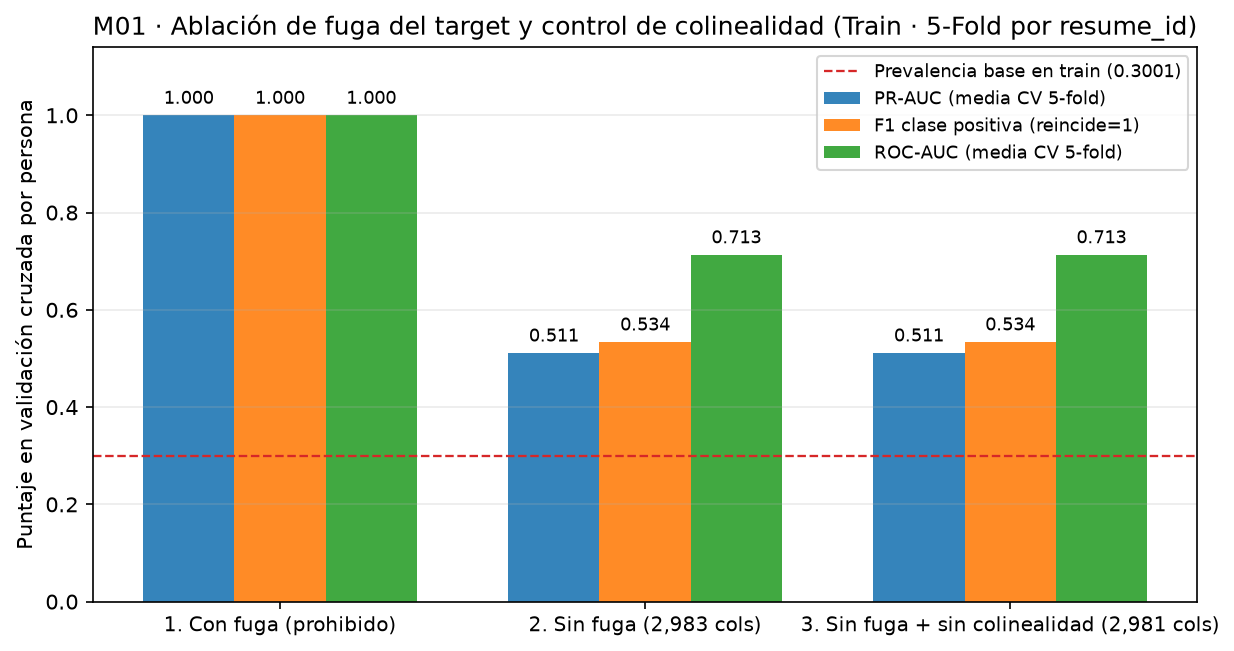

M02: C:\Users\User\Documents\JobPath\MineriaProtect\reports\modelado_jobpath\figures\m02_curvas_pr_y_roc_test.png


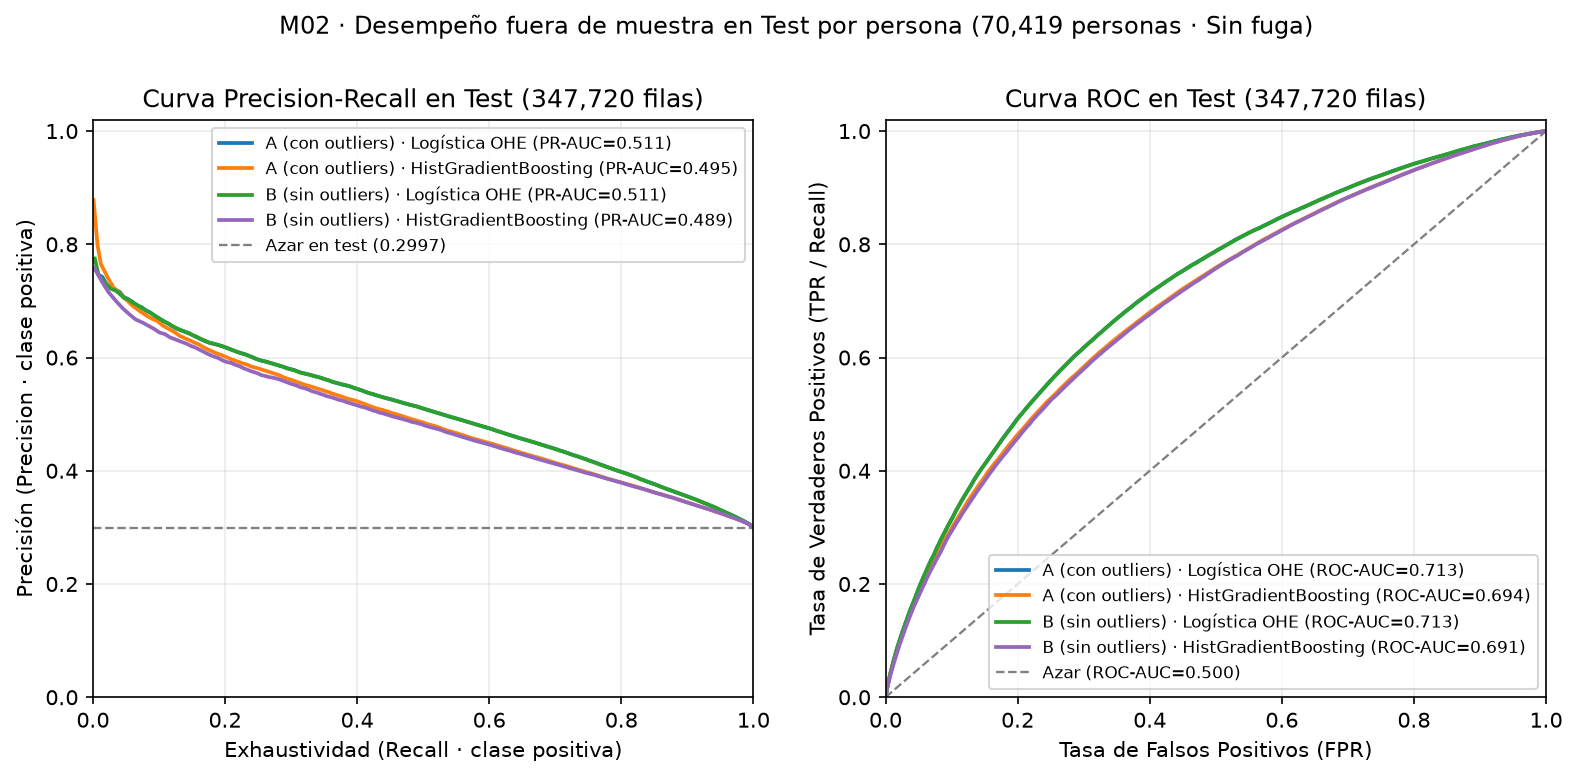

M03: C:\Users\User\Documents\JobPath\MineriaProtect\reports\modelado_jobpath\figures\m03_comparacion_modelos_ab.png


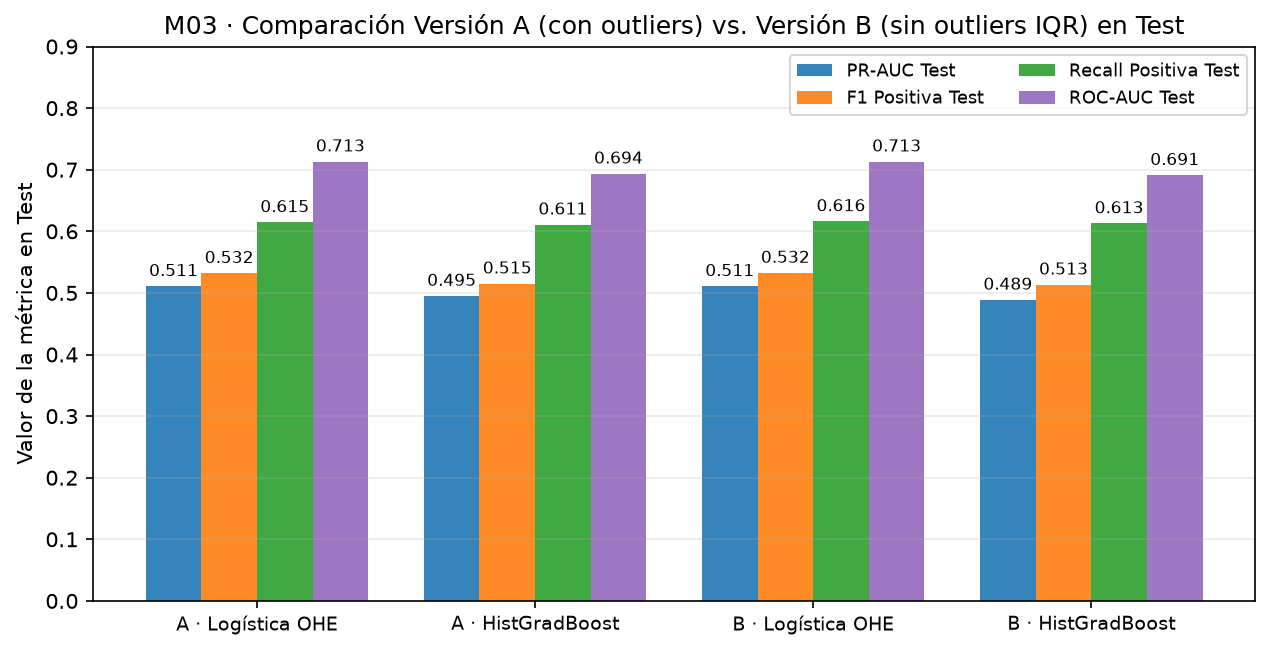

M04: C:\Users\User\Documents\JobPath\MineriaProtect\reports\modelado_jobpath\figures\m04_importancia_variables_sin_fuga.png


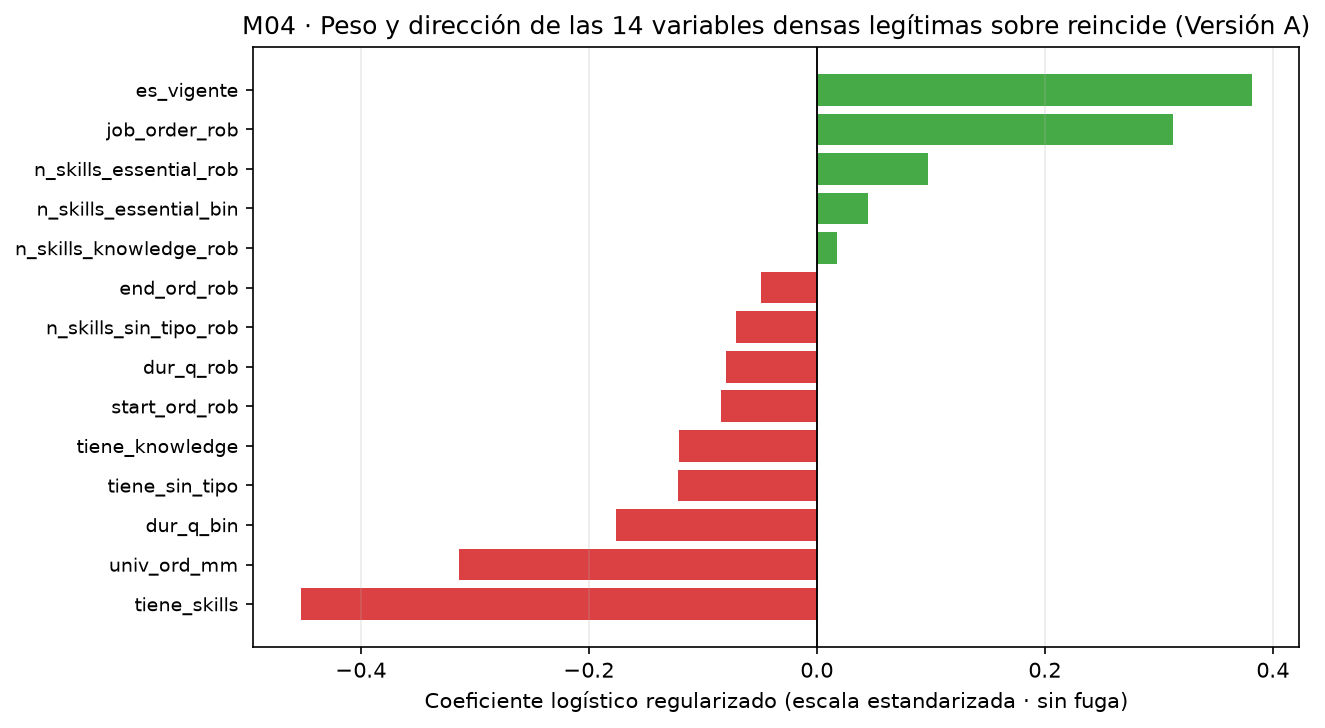

In [5]:
FIGURE_PATHS = PIPELINE.plotter.render_all(EVAL_BUNDLE)
for code, fpath in FIGURE_PATHS.items():
    print(f"{code}: {fpath}")
    display(Image(filename=fpath))

**Lectura.** Las cuatro figuras sintetizan visualmente el cierre de la Fase 4:
- **M01** ilustra por qué la auditoría de fuga era indispensable: el salto entre `1.000` (con fuga) y `0.511` (sin fuga) separa un artefacto circular de un modelo real.
- **M02** muestra que tanto en la curva Precision-Recall (`PR-AUC = 0.511`) como en la curva ROC (`ROC-AUC = 0.713`), la Regresión Logística con las `2,967` ocupaciones OHE domina sobre el modelo solo denso en todos los umbrales de decisión.
- **M03** confirma visualmente la estabilidad entre las versiones A y B.
- **M04** jerarquiza el papel de `tiene_skills`, `es_vigente`, `univ_ord_mm`, `job_order_rob` y `dur_q_bin`.

## 6. Bitácora de decisiones de la Fase 4 y control final de integridad SHA-256

**¿Qué hace?** Construye y exporta las tablas de resultados y la bitácora de decisiones de la Fase 4 en `reports/modelado_jobpath/tables/`, muestra también la bitácora consolidada `bitacora_decisiones_v1_vs_v2.csv` de todo el proyecto y verifica que los 13 archivos de entrada mantienen exactamente la misma huella SHA-256 que al inicio.

**¿Por qué existe?** Cierra el ciclo metodológico CRISP-DM + KDD asegurando trazabilidad completa de decisiones y garantizando que el modelado no alteró ningún insumo de las fases previas.

**¿Qué recibe y qué entrega?** Recibe `SNAPSHOT_BEFORE`, `DATA_A` y `EVAL_BUNDLE`. Entrega las tablas exportadas en disco y el veredicto booleano de integridad.

**Papel en el proyecto.** Certificación final de reproducibilidad del pipeline completo (`2.0 → 3.0 → 4.0 → 4.1 → 5.0 → 6.0`).

In [6]:
DECISION_LOG_F4 = PIPELINE.build_decision_log(DATA_A, EVAL_BUNDLE)
SAVED_TABLES = PIPELINE.save_tables(EVAL_BUNDLE, DECISION_LOG_F4)

print("=== 6.1 Bitácora de decisiones de la Fase 4 (Modelado y Evaluación) ===")
display(DECISION_LOG_F4)

v1_v2_log_path = CONFIG.project_root / "reports" / "eda_jobpath" / "tables" / "bitacora_decisiones_v1_vs_v2.csv"
if v1_v2_log_path.exists():
    print("\n=== 6.2 Bitácora consolidada del proyecto (Antiguo v1 vs. Nuevo v2 · D01 a D14) ===")
    display(pd.read_csv(v1_v2_log_path))

INTEGRITY_DF = PIPELINE.verify_inputs(SNAPSHOT_BEFORE)
print("\n=== 6.3 Verificación SHA-256 de insumos de solo lectura ===")
display(INTEGRITY_DF)

all_intact = bool(INTEGRITY_DF["sin_cambios"].all())
all_figs_exist = all(Path(p).exists() for p in FIGURE_PATHS.values())
zero_cv_overlap = EVAL_BUNDLE.cv_leak_check["personas_solapadas_entre_folds"] == 0

print(f"Todos los insumos intactos (SHA-256): {all_intact}")
print(f"Todas las figuras M01-M04 generadas: {all_figs_exist}")
print(f"Cero personas solapadas en CV y Test: {zero_cv_overlap and DATA_A.verification['personas_solapadas'] == 0}")
assert all_intact and all_figs_exist and zero_cv_overlap

=== 6.1 Bitácora de decisiones de la Fase 4 (Modelado y Evaluación) ===


,id,decision,evidencia_ejecutada,accion_adoptada
0,F4-01,Exclusión obligatoria de columnas con fuga del...,Con veces_ese_oficio_rob/bin el PR-AUC CV es 1...,Se eliminan veces_ese_oficio_rob y veces_ese_o...
1,F4-02,Control de colinealidad en variables numéricas,Se eliminan start_year_rob (r=1.000 con start_...,Se conserva una sola representante por familia...
2,F4-03,Validación cruzada agrupada por persona (Strat...,"5 pliegues sobre 281,674 personas de train con...",Toda selección de hiperparámetros y ablación s...
3,F4-04,Comparación de modelos y versiones A (con outl...,"En test (347,720 filas): Logística OHE alcanza...","Las 2,967 dummies de occupation_code aportan s..."



=== 6.2 Bitácora consolidada del proyecto (Antiguo v1 vs. Nuevo v2 · D01 a D14) ===


,id_decision,fase,componente,decision,valor_antiguo_v1,valor_nuevo_v2,sigue_valida,justificacion_tecnica
0,D01,2.0 Preprocesamiento,Archivo de entrada (Versión A),Fuente maestra con outliers,data/03_processed/empleos_limpio_con_competenc...,data/03_processed/empleos_unificado_limpio.csv...,Actualizada,El nuevo CSV integra las 3 particiones de JobH...
1,D02,2.0 Preprocesamiento,Embudo de conteo (RowCountFunnel),Umbral de alerta de pérdida por etapa,No existía en v1,Alerta automática si una etapa elimina > 5.0% ...,Nueva,Previene pérdidas silenciosas de filas o perso...
2,D03,2.0 Preprocesamiento,Duplicados,Regla de duplicados exactos y clave compuesta,0 duplicados exactos; clave de 3 columnas con ...,0 duplicados exactos; clave de 5 columnas = 0;...,Sí,No se eliminan filas por clave corta porque re...
3,D04,2.0 Preprocesamiento,Categorías y MNAR,Normalización de university_level,"None -> No reportado (42,807 filas = 11.37%)","Ya normalizado a No reportado (205,238 filas =...",Sí,La omisión del nivel educativo es informativa ...
4,D05,2.0 Preprocesamiento,Nulos estructurales MAR y censura,No imputación y conservación de banderas,"28,304 sin occupation_code (7.52%): 25,805 unk...","132,276 sin occupation_code (7.07%): 128,981 u...",Sí,Imputar competencias en oficios no clasificado...
5,D06,2.0 Preprocesamiento,Winsorización IQR (Versión B),Recorte Tukey k=1.5 en 4 columnas de conteo,Límites [-4.5..47.5] / [-4.5..39.5] / [-6.5..1...,Mismos límites exactos [-4.5..47.5] / [-4.5..3...,Sí,Los cuartiles Q1/Q3/IQR son 100% idénticos ent...
6,D07,3.0 Transformación,Universo modelable,Filtro n_skills_essential.notna(),"348,263 filas (92.48%) y 70,397 personas (99.07%)","1,738,738 filas (92.93%) y 352,093 personas (9...",Sí,Los escaladores de scikit-learn requieren valo...
7,D08,3.0 Transformación,Partición por persona,GroupShuffleSplit 80/20 con seed=42 por resume_id,"Train: 278,987 filas (56,317 pers.) / Test: 69...","Train: 1,391,018 filas (281,674 pers.) / Test:...",Sí,Garantiza que ninguna trayectoria individual c...
8,D09,3.0 Transformación,Codificación One-Hot,OneHotEncoder fit_on_train sobre occupation_co...,"2,819 categorías en train -> X con 2,839 colum...","2,967 dummies occupation_code_* en X -> X con ...",Actualizada,El universo completo incorpora +146 dummies de...
9,D10,3.0 Transformación,Escalado y discretización,RobustScaler (10 cols) + MinMaxScaler (univ_or...,"Ajustados solo en train (278,987 filas)","Ajustados solo en train (1,391,018 filas) y ve...",Sí,Evita contaminación del conjunto de prueba y m...



=== 6.3 Verificación SHA-256 de insumos de solo lectura ===


,archivo,ruta,sha256_antes,sha256_despues,sin_cambios
0,empleos_unificado_limpio.csv,C:\Users\User\Documents\JobPath\MineriaProtect...,ae0cbc6ebd86bcf3…,ae0cbc6ebd86bcf3…,True
1,empleos_limpio_con_competencias_sin_outliers.csv,C:\Users\User\Documents\JobPath\MineriaProtect...,de8515e31565ca0b…,de8515e31565ca0b…,True
2,split_map_resume_id.csv,C:\Users\User\Documents\JobPath\MineriaProtect...,67dd3e3d68e1ff5e…,67dd3e3d68e1ff5e…,True
3,X_train.csv,C:\Users\User\Documents\JobPath\MineriaProtect...,84326e5737831b79…,84326e5737831b79…,True
4,y_train.csv,C:\Users\User\Documents\JobPath\MineriaProtect...,07d22441c00832e8…,07d22441c00832e8…,True
5,X_test.csv,C:\Users\User\Documents\JobPath\MineriaProtect...,785a51c74e626e9f…,785a51c74e626e9f…,True
6,y_test.csv,C:\Users\User\Documents\JobPath\MineriaProtect...,38f822d6ac471ec8…,38f822d6ac471ec8…,True
7,transformers.joblib,C:\Users\User\Documents\JobPath\MineriaProtect...,b64f676458f3ef33…,b64f676458f3ef33…,True
8,X_train.csv,C:\Users\User\Documents\JobPath\MineriaProtect...,5bca3c92a9043c9b…,5bca3c92a9043c9b…,True
9,y_train.csv,C:\Users\User\Documents\JobPath\MineriaProtect...,07d22441c00832e8…,07d22441c00832e8…,True


Todos los insumos intactos (SHA-256): True
Todas las figuras M01-M04 generadas: True
Cero personas solapadas en CV y Test: True


**Lectura.** Los tres controles finales devuelven `True`:
- **Insumos intactos (`True`):** Ninguno de los archivos de `data/03_processed/`, `data/04_transformed/` ni `split_map_resume_id.csv` sufrió modificaciones.
- **Figuras y tablas completas (`True`):** Las 4 figuras (`M01`–`M04`) y las 5 tablas CSV quedaron guardadas en `reports/modelado_jobpath/`, y la bitácora maestra `bitacora_decisiones_v1_vs_v2.csv` (`D01`–`D14`) quedó persistida en `reports/eda_jobpath/tables/`.
- **Cero fuga y cero solapamiento de personas (`True`):** Todo el entrenamiento, validación cruzada y prueba respetó estrictamente la partición por `resume_id` y la exclusión de variables circulares.